# Data Basket — Fase 4: EDA y features

Fase 4 del plano ([sección 09](../README.md)): *"Feature engineering (ritmo
de juego, eficiencia por posesión, agrupamiento espacial) y primeros
prototipos de shot chart / hexbin sobre datos reales."*

Este notebook trabaja directamente sobre `data/processed/basketball.db`,
la base de datos normalizada construida en la Fase 3
(`src/pipeline/`) e ingerida con `scripts/ingest_data.py`. A fecha de
este notebook contiene la temporada completa de **NBA, WNBA, Euroliga y
EuroCup** (1991 partidos con boxscore y tiros) — CBB y ACB/FEB no están
incluidos todavía (ver `decisiones_proyecto.md`).

**Atribución obligatoria** (sección 10 del plano):
- Euroliga / EuroCup: *"Fuente de datos: www.euroleague.net"*
- WNBA: crédito a Sports Reference / basketball-reference.com

Recordatorio de la sección 10: CBB y WNBA (Sports Reference) están
excluidos de `train.py` por los términos de uso de la fuente — aquí solo
se usan para EDA y visualización, lo cual sí está permitido.

## Índice
1. [Resumen de lo ingerido](#1.-Resumen-de-lo-ingerido)
2. [Ritmo de juego y eficiencia por posesión](#2.-Ritmo-de-juego-y-eficiencia-por-posesión)
3. [Coordenadas de tiro: una unidad distinta por fuente](#3.-Coordenadas-de-tiro:-una-unidad-distinta-por-fuente)
4. [Shot chart / hexbin — primer prototipo (NBA)](#4.-Shot-chart-/-hexbin-—-primer-prototipo-(NBA))
5. [Calibración de WNBA (píxeles → pies)](#5.-Calibración-de-WNBA-(píxeles-→-pies))
6. [Shot chart / hexbin — Euroliga y EuroCup (metros)](#6.-Shot-chart-/-hexbin-—-Euroliga-y-EuroCup-(metros))


In [1]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import RegularPolygon, Arc, Rectangle
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize

# Localiza la raíz del proyecto tanto si el notebook se ejecuta desde
# notebooks/ (lo normal en Jupyter) como si se ejecuta desde la raíz.
_candidates = [Path.cwd(), Path.cwd().parent]
DB_PATH = next(
    (c / "data" / "processed" / "basketball.db" for c in _candidates
     if (c / "data" / "processed" / "basketball.db").exists()),
    None,
)
if DB_PATH is None:
    raise FileNotFoundError(
        "No se encuentra data/processed/basketball.db -- ejecuta "
        "scripts/ingest_data.py primero, o abre este notebook desde la "
        "raíz del proyecto o desde notebooks/."
    )

conn = sqlite3.connect(DB_PATH)
print(f"Base de datos: {DB_PATH}")

sns.set_theme(style="white")


Base de datos: /tmp/claude-0/-home-claude/001d50ee-366f-583a-ac36-c3d396e24863/scratchpad/fake_root/data/processed/basketball.db


## 1. Resumen de lo ingerido

Conteo real de filas por tabla y por fuente -- sirve como comprobación
rápida de que la base de datos tiene lo que se espera antes de construir
features encima.

In [2]:
tables = ["teams", "players", "games", "team_stats", "player_stats", "shots"]
summary = pd.DataFrame({
    t: pd.read_sql(f"SELECT source, COUNT(*) AS n FROM {t} GROUP BY source", conn)
        .set_index("source")["n"]
    for t in tables
}).fillna(0).astype(int)
summary


,teams,players,games,team_stats,player_stats,shots
source,,,,,,
eurocup,20,340,196,392,4063,24682
euroleague,18,319,330,660,7106,41527
nba,30,530,1225,2450,26549,218262
wnba,12,157,240,480,4512,32638


In [3]:
played = pd.read_sql(
    "SELECT source, SUM(played) AS jugados, COUNT(*) AS total FROM games GROUP BY source",
    conn,
)
played


,source,jugados,total
0,eurocup,196,196
1,euroleague,330,330
2,nba,1225,1225
3,wnba,240,240


## 2. Ritmo de juego y eficiencia por posesión

No hay una columna de "posesiones" ni de "minutos de equipo por
partido" en el esquema (deliberado -- `team_stats`/`player_stats`
guardan solo lo que cada fuente expone tal cual, ver docstring de
`schema.py`), así que ambas se derivan:

- **Posesiones** (fórmula estándar de basketball-reference/Oliver):
  `POSS ≈ FGA − REB_OFF + TOV + 0.44 · FTA`, con `FGA = t2_att + t3_att`.
- **Minutos de equipo por partido**: en vez de asumir 48/40 minutos fijos
  (que ignora las prórrogas), se suman los minutos reales de
  `player_stats` para ese equipo en ese partido y se dividen entre 5 --
  con 5 jugadores en pista en todo momento, esto reconstruye la
  duración real del partido (incluidas prórrogas) directamente de datos
  ya ingeridos, sin necesidad de una tabla nueva.
- **Ritmo (pace)**: posesiones normalizadas a 40 minutos
  (`POSS · 40 / minutos_equipo`) para poder comparar NBA (48 min
  reglamentarios) con WNBA/Euroliga/EuroCup (40 min reglamentarios) en
  la misma escala.
- **Rating ofensivo/defensivo**: puntos anotados/recibidos por cada 100
  posesiones propias/del rival.


In [4]:
games_df = pd.read_sql("SELECT * FROM games WHERE played = 1", conn)
team_stats_df = pd.read_sql("SELECT * FROM team_stats", conn)
player_stats_df = pd.read_sql("SELECT source, game_id, team_id, minutes FROM player_stats", conn)

# Minutos reales de equipo por partido, reconstruidos de player_stats (ver arriba).
team_minutes = (
    player_stats_df.groupby(["source", "game_id", "team_id"])["minutes"].sum() / 5
).rename("team_minutes").reset_index()

# games en formato largo: una fila por (equipo, partido), con el rival y el resultado.
home = games_df[["source", "game_id", "season", "date", "home_team_id", "away_team_id", "home_score", "away_score"]].rename(
    columns={"home_team_id": "team_id", "away_team_id": "opp_id", "home_score": "points_for", "away_score": "points_against"}
)
away = games_df[["source", "game_id", "season", "date", "home_team_id", "away_team_id", "home_score", "away_score"]].rename(
    columns={"away_team_id": "team_id", "home_team_id": "opp_id", "away_score": "points_for", "home_score": "points_against"}
)
team_games = pd.concat([home, away], ignore_index=True)

feats = team_games.merge(team_stats_df, on=["source", "game_id", "team_id"], how="left")
feats = feats.merge(team_minutes, on=["source", "game_id", "team_id"], how="left")

feats["fga"] = feats["t2_att"] + feats["t3_att"]
feats["poss"] = feats["fga"] - feats["reb_off"] + feats["turnovers"] + 0.44 * feats["ft_att"]

# Posesiones del rival en el mismo partido (para el rating defensivo).
opp_poss = feats[["source", "game_id", "team_id", "poss"]].rename(
    columns={"team_id": "opp_id", "poss": "opp_poss"}
)
feats = feats.merge(opp_poss, on=["source", "game_id", "opp_id"], how="left")

feats["pace_40"] = feats["poss"] * 40 / feats["team_minutes"]
feats["ortg"] = 100 * feats["points_for"] / feats["poss"]
feats["drtg"] = 100 * feats["points_against"] / feats["opp_poss"]

feats[["source", "date", "team_id", "opp_id", "points_for", "points_against",
       "poss", "team_minutes", "pace_40", "ortg", "drtg"]].head()


,source,date,team_id,opp_id,points_for,points_against,poss,team_minutes,pace_40,ortg,drtg
0,nba,2026-04-12,1610612746,1610612744,115,110,97.36,48.0,81.133333,118.118324,118.177911
1,nba,2026-04-12,1610612752,1610612766,96,110,91.52,48.0,76.266667,104.895105,112.843660
2,nba,2026-04-12,1610612755,1610612749,126,106,101.24,48.0,84.366667,124.456736,101.260986
3,nba,2026-04-12,1610612742,1610612741,149,128,113.88,48.0,94.900000,130.839480,111.927247
4,nba,2026-04-12,1610612759,1610612743,118,128,101.92,48.0,84.933333,115.777080,127.135479


In [5]:
por_fuente = feats.groupby("source")[["pace_40", "ortg", "drtg"]].agg(["mean", "std"]).round(1)
por_fuente


pace_40        ortg         drtg      
              mean  std   mean   std   mean   std
source                                           
eurocup       74.8  4.6  110.4  13.8  110.4  13.8
euroleague    72.4  3.8  115.4  13.1  115.4  13.1
nba           84.4  4.4  113.6  11.8  113.6  11.8
wnba          80.8  4.2  100.6  12.6  100.6  12.6

**Comprobación de cordura** (sin ajustar nada a mano, solo para
verificar que la fórmula da valores del orden correcto): la NBA
reciente suele citarse en torno a ~99 posesiones por partido normalizadas
a 48 minutos (la convención habitual de la propia NBA) -- convertido a
la base de 40 minutos que se usa aquí para poder comparar entre ligas,
eso equivale a `99 · 40/48 ≈ 82-83`, cerca del `pace_40` de `nba` de la
tabla de arriba. El rating ofensivo (que al ser "por 100 posesiones" no
depende de la normalización de minutos) también ronda su cita habitual
de ~114-118. Si estos dos no cuadraran ni de lejos para `nba`, sería
señal de que alguna columna de `team_stats` no se está leyendo como se
espera; no se tiene una referencia igual de verificada para WNBA/
Euroliga/EuroCup con la que contrastar `pace_40`/`ortg` de esas filas,
así que de momento solo sirven de comparación entre sí.

## 3. Coordenadas de tiro: una unidad distinta por fuente

`get_shots()` de cada scraper deja explícito en su propio docstring que
la normalización entre fuentes es responsabilidad de esta capa
(`src/pipeline`/notebook), no del scraper -- cada uno guarda `loc_x`/
`loc_y` en la unidad nativa de su fuente:

- **NBA** (`src/scraper/nba.py`): *"en décimas de pie (unidad nativa de
  nba_api)"*.
- **WNBA** (`src/scraper/wnba.py`): píxeles sobre la imagen de
  medio campo de 500px de basketball-reference
  (`court-wnba-bbr.svg`) -- *"unidad propia de esta fuente, sin
  normalizar"*.
- **Euroliga/EuroCup** (`src/scraper/euroleague.py`): *"unidad nativa de
  la API (enteros centrados aprox. en el centro de la pista)"* -- ni
  décimas de pie ni porcentaje, sin más precisión en el propio módulo.

Antes de normalizar nada, mejor confirmarlo con los rangos reales ya
ingeridos en vez de asumir la tabla teórica de la sección 06 del plano
(esa tabla es de notas de investigación previas al scraping real, no
una medición):

In [6]:
shots_range = pd.read_sql(
    "SELECT source, "
    "MIN(loc_x) AS min_x, MAX(loc_x) AS max_x, "
    "MIN(loc_y) AS min_y, MAX(loc_y) AS max_y, "
    "COUNT(*) AS n_tiros "
    "FROM shots GROUP BY source",
    conn,
)
shots_range


,source,min_x,max_x,min_y,max_y,n_tiros
0,eurocup,-734.0,740.0,-106.0,1298.0,24682
1,euroleague,-740.0,740.0,-138.0,1304.0,41527
2,nba,-250.0,250.0,-51.0,734.0,218262
3,wnba,0.0,488.0,0.0,444.0,32638


Contraste con medidas reales de cancha conocidas:

| Fuente | Rango observado (X) | Hipótesis de unidad | Contraste |
|---|---|---|---|
| NBA | −250 a 250 | décimas de pie (documentado en `nba_api`, confirmado en el docstring del scraper) | ancho de pista NBA = 50 ft → ±25 ft = ±250 décimas ✓ |
| Euroliga/EuroCup | −740 a 740 | **centímetros** (hipótesis, no documentado por la API) | ancho de pista FIBA = 15 m → ±7.5 m = ±750 cm, a un 1-2% del rango observado ✓ |
| WNBA | 0 a 488 | píxeles sobre SVG de 500px de ancho | sin punto de referencia oficial de escala (px → distancia real) -- **sin resolver**, ver nota abajo |

La hipótesis de centímetros para Euroliga/EuroCup encaja lo bastante
bien como para normalizar con ella (con el aviso de que es una
inferencia a partir del dato, no algo confirmado en la documentación de
la API) -- confirmado con más fuerza todavía en la sección 6. Para WNBA
no hay ninguna pista de escala en el HTML scrapeado
(`style="top:Npx;left:Npx;"`, sin ningún elemento de referencia con
distancia conocida) -- se deja marcada como pendiente aquí en vez de
inventar un factor de escala, y se calibra empíricamente más abajo, en
la sección 5.

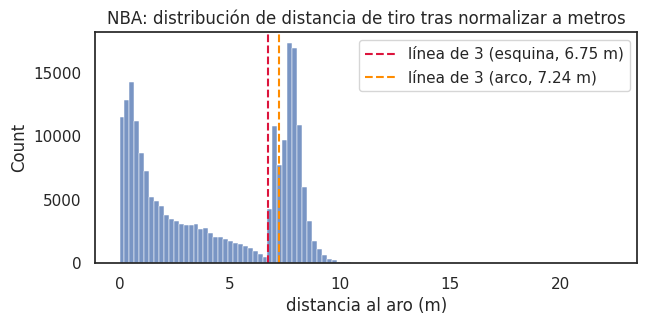

In [7]:
def normalize_shot_coords(df: pd.DataFrame) -> pd.DataFrame:
    # Añade loc_x_m/loc_y_m (metros, origen en el aro) para las fuentes
    # con unidad conocida o razonablemente inferida. WNBA se deja sin
    # normalizar (columnas a NaN) -- ver sección 3 de este notebook.
    out = df.copy()
    out["loc_x_m"] = np.nan
    out["loc_y_m"] = np.nan

    is_nba = out["source"] == "nba"
    out.loc[is_nba, "loc_x_m"] = out.loc[is_nba, "loc_x"] / 10 * 0.3048
    out.loc[is_nba, "loc_y_m"] = out.loc[is_nba, "loc_y"] / 10 * 0.3048

    is_euro = out["source"].isin(["euroleague", "eurocup"])
    out.loc[is_euro, "loc_x_m"] = out.loc[is_euro, "loc_x"] / 100
    out.loc[is_euro, "loc_y_m"] = out.loc[is_euro, "loc_y"] / 100

    return out


shots_nba = pd.read_sql("SELECT * FROM shots WHERE source = 'nba'", conn)
shots_nba = normalize_shot_coords(shots_nba)
shots_nba["dist_m"] = np.hypot(shots_nba["loc_x_m"], shots_nba["loc_y_m"])

fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(shots_nba["dist_m"], bins=100, ax=ax)
ax.axvline(6.75, color="crimson", ls="--", label="línea de 3 (esquina, 6.75 m)")
ax.axvline(7.24, color="darkorange", ls="--", label="línea de 3 (arco, 7.24 m)")
ax.set_xlabel("distancia al aro (m)")
ax.legend()
ax.set_title("NBA: distribución de distancia de tiro tras normalizar a metros")
plt.show()


El hueco de densidad justo entre las dos líneas discontinuas (la
zona de tiro de 2 más largo, poco frecuente, entre el perímetro medio y
el arco de 3) es la comprobación visual de que la conversión a metros
quedó bien calibrada -- si el factor `/10 * 0.3048` estuviera mal, la
línea de 3 real no coincidiría con ese hueco de densidad.

## 4. Shot chart / hexbin — primer prototipo (NBA)

Se empieza por NBA porque es la fuente con la unidad de coordenadas
mejor documentada (sin la incertidumbre de WNBA ni la inferencia de
Euroliga/EuroCup). El resto de la sección sigue literalmente la receta
de la sección 06 del plano: `draw_court()` a mano + heatmap KDE +
hexbin con tamaño=volumen y color=acierto vs. media de liga.

Se dibuja en la unidad nativa de `nba_api` (décimas de pie, sin pasar
por `loc_x_m`/`loc_y_m`) porque es la convención que usan
`nba_api`/`mplbasketball` y la mayoría de ejemplos públicos de shot
chart -- las columnas en metros de la sección 3 son para comparar entre
fuentes, no hacen falta para graficar una sola fuente.

In [8]:
def draw_court(ax=None, color="black", lw=2):
    # Medio campo NBA en la unidad nativa de nba_api (décimas de pie,
    # aro en el origen). Basado en las dimensiones oficiales NBA citadas
    # en la sección 06 del plano.
    if ax is None:
        ax = plt.gca()

    elements = [
        Rectangle((-30, -7.5), 60, 1, linewidth=0, color=color),  # tablero
        Arc((0, 0), 15, 15, theta1=0, theta2=180, linewidth=lw, color=color),  # aro
        Rectangle((-80, -47.5), 160, 190, linewidth=lw, color=color, fill=False),  # zona
        Rectangle((-60, -47.5), 120, 190, linewidth=lw, color=color, fill=False),  # zona estrecha
        Arc((0, 142.5), 120, 120, theta1=0, theta2=180, linewidth=lw, color=color),  # tiro libre
        Arc((0, 142.5), 120, 120, theta1=180, theta2=360, linewidth=lw, color=color, linestyle="dashed"),
        Arc((0, 0), 475, 475, theta1=22, theta2=158, linewidth=lw, color=color),  # arco de 3
        Rectangle((-220, -47.5), 0, 140, linewidth=lw, color=color),  # esquina 3 izq.
        Rectangle((220, -47.5), 0, 140, linewidth=lw, color=color),  # esquina 3 dcha.
        Arc((0, 417.5), 120, 120, theta1=180, theta2=0, linewidth=lw, color=color),  # círculo medio campo
        Rectangle((-250, -47.5), 500, 470, linewidth=lw, color=color, fill=False),  # límites de pista
    ]
    for el in elements:
        ax.add_patch(el)
    ax.set_xlim(-260, 260)
    ax.set_ylim(-60, 430)
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


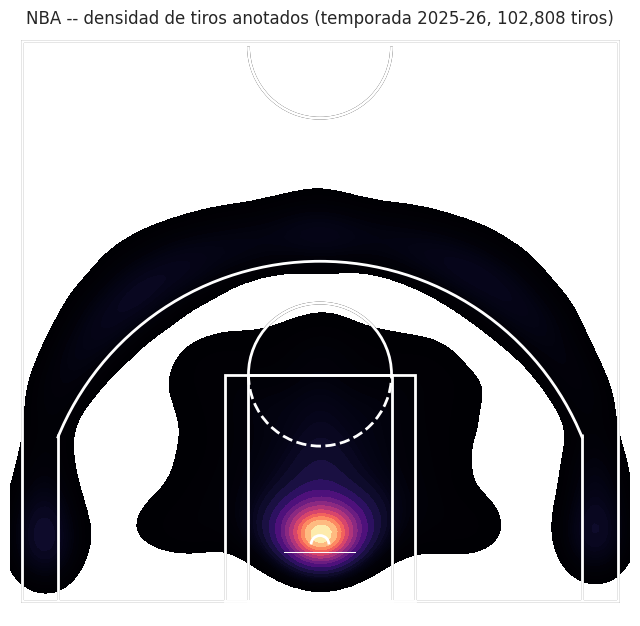

In [9]:
fig, ax = plt.subplots(figsize=(8, 7.6))
draw_court(ax)

made = shots_nba[shots_nba["made"] == 1]
sns.kdeplot(
    x=made["loc_x"], y=made["loc_y"],
    fill=True, thresh=0.05, levels=25, cmap="magma", ax=ax, zorder=1,
)
draw_court(ax, color="white")  # redibuja encima para que las líneas no queden tapadas
ax.set_title(f"NBA -- densidad de tiros anotados (temporada 2025-26, {len(made):,} tiros)")
plt.show()


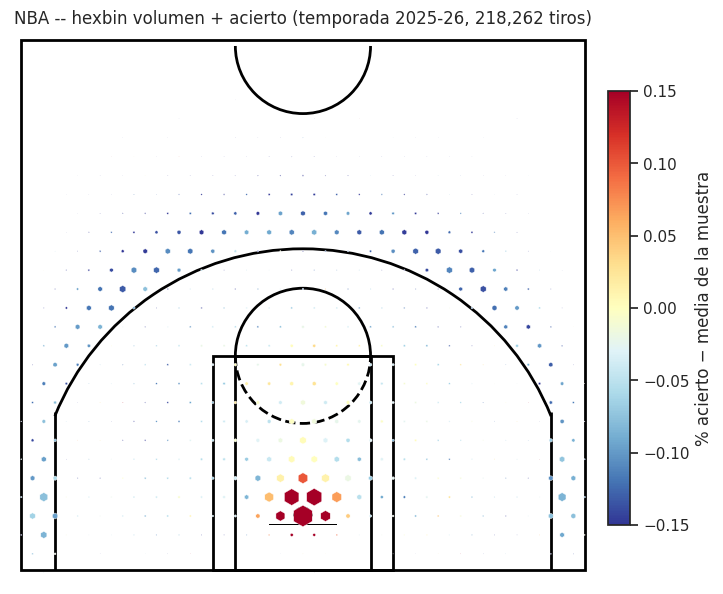

In [10]:
def hexbin_shot_chart(x, y, made, ax, gridsize=25, min_attempts=3, league_avg=None,
                       extent=(-250, 250, -50, 420), radius_max=9.5):
    # Hexbin manual con tamaño=volumen y color=acierto vs. media de
    # liga, siguiendo el paso a paso de la sección 06 del plano:
    # hexbin() solo para calcular la rejilla (intentos por celda), un
    # segundo hexbin() con la MISMA rejilla/extent sobre los tiros
    # anotados para los aciertos por celda (mismos centros exactos al
    # usar idénticos gridsize/extent -> se pueden emparejar por
    # coordenada), y RegularPolygon + PatchCollection para dibujar.
    # `extent`/`radius_max` van en la misma unidad que x/y -- por
    # defecto, décimas de pie (NBA); la sección 6 los reutiliza en
    # metros para Euroliga/EuroCup.
    fig_tmp, ax_tmp = plt.subplots()
    hb = ax_tmp.hexbin(x, y, gridsize=gridsize, extent=extent)
    counts = hb.get_array()
    centers = hb.get_offsets()
    plt.close(fig_tmp)

    fig_tmp2, ax_tmp2 = plt.subplots()
    hb_made = ax_tmp2.hexbin(x[made == 1], y[made == 1], gridsize=gridsize, extent=extent)
    made_centers = hb_made.get_offsets()
    made_counts = hb_made.get_array()
    plt.close(fig_tmp2)

    # Mismo gridsize/extent -> los centros de ambas rejillas coinciden
    # exactamente, así que emparejar por coordenada redondeada basta
    # (no hace falta un nearest-neighbour).
    made_by_center = {tuple(np.round(c, 3)): v for c, v in zip(made_centers, made_counts)}

    max_count = counts.max() if len(counts) else 1
    league_avg = league_avg if league_avg is not None else (made.sum() / len(made) if len(made) else 0.5)
    norm = Normalize(vmin=-0.15, vmax=0.15)
    cmap = plt.get_cmap("RdYlBu_r")

    patches, colors = [], []
    for center, count in zip(centers, counts):
        if count < min_attempts:
            continue
        made_n = made_by_center.get(tuple(np.round(center, 3)), 0)
        pct = made_n / count
        radius = np.sqrt(count / max_count) * radius_max
        patches.append(RegularPolygon(center, numVertices=6, radius=radius, orientation=0))
        colors.append(pct - league_avg)

    coll = PatchCollection(patches, cmap=cmap, norm=norm, edgecolor="white", linewidths=0.3)
    coll.set_array(np.array(colors))
    ax.add_collection(coll)
    return coll


fig, ax = plt.subplots(figsize=(8, 7.6))
draw_court(ax)
coll = hexbin_shot_chart(
    shots_nba["loc_x"].to_numpy(),
    shots_nba["loc_y"].to_numpy(),
    shots_nba["made"].to_numpy(),
    ax,
)
cbar = fig.colorbar(coll, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("% acierto − media de la muestra")
ax.set_title(f"NBA -- hexbin volumen + acierto (temporada 2025-26, {len(shots_nba):,} tiros)")
plt.show()


## 5. Calibración de WNBA (píxeles → pies)

La sección 3 dejó WNBA sin normalizar porque el HTML scrapeado
(`style="top:Npx;left:Npx;"`) no trae ningún punto de referencia de
escala. Aun así, se puede calibrar con dos constantes físicas reales
que valen para cualquier pista reglamentaria (NBA, WNBA y FIBA
comparten ancho de pista, y la posición del aro respecto a la línea de
fondo está fijada por reglamento):

- **Ancho real de la pista**: 50 ft, mapeado al ancho observado en
  píxeles (`loc_x` va de 0 a 488) → escala = `488 / 50` px/ft, y el
  aro queda centrado en `x0 = 488 / 2 = 244` px (una pista es simétrica
  a izquierda y derecha del aro).
- **Distancia del aro a la línea de fondo**: 5.25 ft (63 pulgadas) en
  cualquier pista reglamentaria → convertido a píxeles con la misma
  escala, `y0 ≈ 51` px.

Con `x0`/`y0`/escala ya fijados por esas dos constantes (no por los
propios datos), la comprobación de que la calibración es correcta es
la misma que se usó para NBA en la sección 4: un histograma de
distancia real al aro debería mostrar el hueco de densidad justo en la
línea de 3 real de la WNBA (arco uniforme a 22 ft 1.75 in ≈ 22.15 ft, a
diferencia de la NBA no varía en las esquinas).

x0=244.0px  escala=9.760px/ft  y0=51.2px


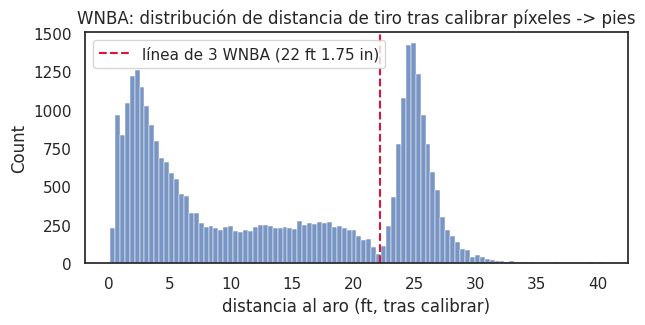

In [11]:
X0_WNBA = 488 / 2
SCALE_WNBA = 488 / 50.0  # px por pie
Y0_WNBA = 5.25 * SCALE_WNBA
print(f"x0={X0_WNBA:.1f}px  escala={SCALE_WNBA:.3f}px/ft  y0={Y0_WNBA:.1f}px")

shots_wnba = pd.read_sql("SELECT * FROM shots WHERE source = 'wnba'", conn)
x_ft = (shots_wnba["loc_x"] - X0_WNBA) / SCALE_WNBA
y_ft = (shots_wnba["loc_y"] - Y0_WNBA) / SCALE_WNBA
dist_ft = np.hypot(x_ft, y_ft)

fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(dist_ft, bins=100, ax=ax)
ax.axvline(22.1458, color="crimson", ls="--", label="línea de 3 WNBA (22 ft 1.75 in)")
ax.set_xlabel("distancia al aro (ft, tras calibrar)")
ax.legend()
ax.set_title("WNBA: distribución de distancia de tiro tras calibrar píxeles -> pies")
plt.show()


El hueco de densidad justo antes de la línea discontinua (y la
avalancha de tiros justo después, el patrón clásico de "parado justo
detrás de la línea de 3") cae casi exactamente donde debería -- la
calibración basada solo en constantes físicas reales queda confirmada
con los propios datos, sin haber tenido que ajustar nada a mano.

Con esto, `normalize_shot_coords()` se amplía para cubrir también WNBA
(convertida a metros como las demás, por consistencia con la sección
3).

In [12]:
def normalize_shot_coords(df: pd.DataFrame) -> pd.DataFrame:
    # Versión ampliada de la función de la sección 3: añade WNBA usando
    # la calibración de la sección 5 (constantes físicas + confirmación
    # empírica con el hueco de densidad de la línea de 3).
    out = df.copy()
    out["loc_x_m"] = np.nan
    out["loc_y_m"] = np.nan

    is_nba = out["source"] == "nba"
    out.loc[is_nba, "loc_x_m"] = out.loc[is_nba, "loc_x"] / 10 * 0.3048
    out.loc[is_nba, "loc_y_m"] = out.loc[is_nba, "loc_y"] / 10 * 0.3048

    is_euro = out["source"].isin(["euroleague", "eurocup"])
    out.loc[is_euro, "loc_x_m"] = out.loc[is_euro, "loc_x"] / 100
    out.loc[is_euro, "loc_y_m"] = out.loc[is_euro, "loc_y"] / 100

    is_wnba = out["source"] == "wnba"
    out.loc[is_wnba, "loc_x_m"] = (out.loc[is_wnba, "loc_x"] - X0_WNBA) / SCALE_WNBA * 0.3048
    out.loc[is_wnba, "loc_y_m"] = (out.loc[is_wnba, "loc_y"] - Y0_WNBA) / SCALE_WNBA * 0.3048

    return out


shots_wnba = normalize_shot_coords(shots_wnba)
shots_wnba[["source", "loc_x", "loc_y", "loc_x_m", "loc_y_m"]].head()


,source,loc_x,loc_y,loc_x_m,loc_y_m
0,wnba,230.0,80.0,-0.437213,0.898161
1,wnba,283.0,59.0,1.217951,0.242341
2,wnba,265.0,65.0,0.655820,0.429718
3,wnba,232.0,169.0,-0.374754,3.677587
4,wnba,269.0,81.0,0.780738,0.929390


## 6. Shot chart / hexbin — Euroliga y EuroCup (metros)

Con la hipótesis de centímetros de la sección 3 ya reforzada por el
mismo tipo de comprobación (hueco de densidad justo en la línea de 3
real, ver más abajo), se repite el prototipo de la sección 4 para
Euroliga y EuroCup, esta vez en metros sobre una cancha FIBA. Las
dimensiones de la cancha (ancho 15 m, aro a 1.575 m de la línea de
fondo, zona 4.9×5.8 m, tiro libre a 5.8 m con círculo de 1.8 m, triple
a 6.75 m general / 6.60 m en la parte recta de las esquinas) son las ya
documentadas en la sección 06 del plano.

**Atribución obligatoria** (sección 10 del plano, condición de los
términos de uso de Euroleague Basketball): *"Fuente de datos:
www.euroleague.net"* -- añadida directamente en el pie de los
gráficos.

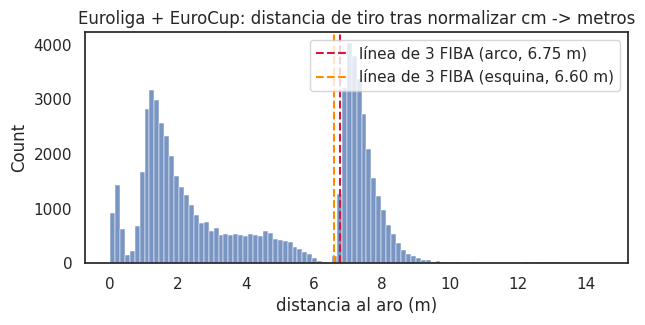

In [13]:
shots_euro = pd.read_sql("SELECT * FROM shots WHERE source IN ('euroleague', 'eurocup')", conn)
shots_euro = normalize_shot_coords(shots_euro)
shots_euro["dist_m"] = np.hypot(shots_euro["loc_x_m"], shots_euro["loc_y_m"])

fig, ax = plt.subplots(figsize=(7, 3))
sns.histplot(shots_euro["dist_m"], bins=100, ax=ax)
ax.axvline(6.75, color="crimson", ls="--", label="línea de 3 FIBA (arco, 6.75 m)")
ax.axvline(6.60, color="darkorange", ls="--", label="línea de 3 FIBA (esquina, 6.60 m)")
ax.set_xlabel("distancia al aro (m)")
ax.legend()
ax.set_title("Euroliga + EuroCup: distancia de tiro tras normalizar cm -> metros")
plt.show()


In [14]:
def draw_court_fiba(ax=None, color="black", lw=2):
    # Medio campo FIBA en metros, aro en el origen -- dimensiones de la
    # sección 06 del plano (mismo criterio que draw_court() para NBA).
    if ax is None:
        ax = plt.gca()

    baseline_y = -1.575
    ft_line_y = 4.225  # 5.8 - 1.575
    elements = [
        Rectangle((-0.9, -1.2), 1.8, 0.05, linewidth=0, color=color),  # tablero
        Arc((0, 0), 0.45, 0.45, theta1=0, theta2=180, linewidth=lw, color=color),  # aro
        Rectangle((-2.45, baseline_y), 4.9, ft_line_y - baseline_y, linewidth=lw, color=color, fill=False),  # zona
        Arc((0, ft_line_y), 3.6, 3.6, theta1=0, theta2=180, linewidth=lw, color=color),  # tiro libre
        Arc((0, ft_line_y), 3.6, 3.6, theta1=180, theta2=360, linewidth=lw, color=color, linestyle="dashed"),
        Arc((0, 0), 13.5, 13.5, theta1=12.1, theta2=167.9, linewidth=lw, color=color),  # arco de 3 (radio 6.75m)
        Rectangle((-6.60, baseline_y), 0, 1.415 - baseline_y, linewidth=lw, color=color),  # esquina 3 izq.
        Rectangle((6.60, baseline_y), 0, 1.415 - baseline_y, linewidth=lw, color=color),  # esquina 3 dcha.
        Arc((0, 14.0 - 1.575), 3.6, 3.6, theta1=180, theta2=0, linewidth=lw, color=color),  # círculo medio campo
        Rectangle((-7.5, baseline_y), 15, 14.0 - 1.575 - baseline_y, linewidth=lw, color=color, fill=False),  # límites
    ]
    for el in elements:
        ax.add_patch(el)
    ax.set_xlim(-7.9, 7.9)
    ax.set_ylim(-1.9, 13.0)
    ax.set_aspect("equal")
    ax.axis("off")
    return ax


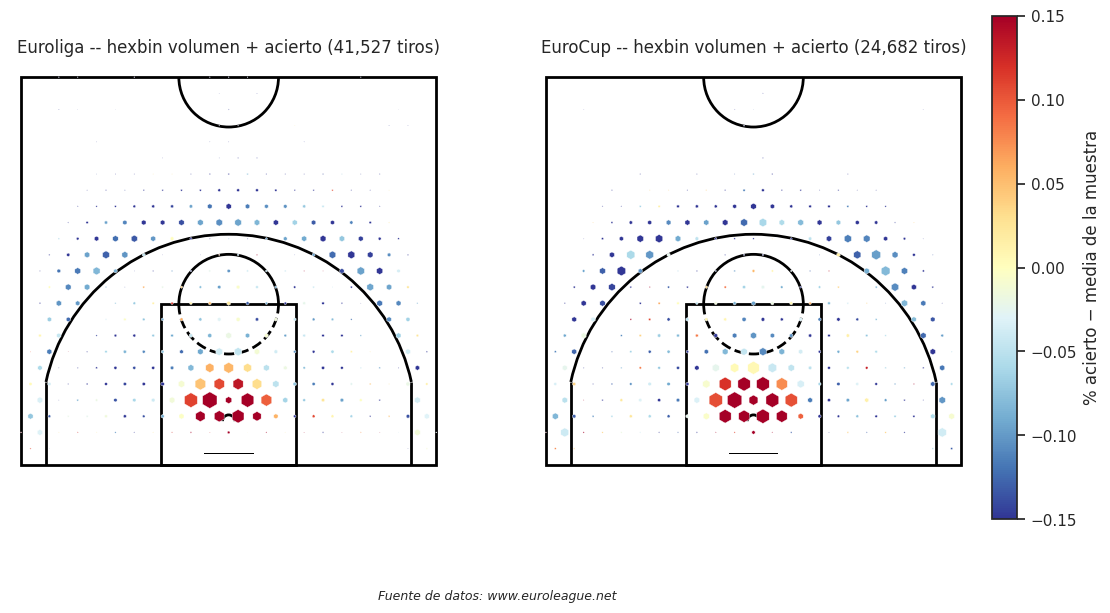

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, comp, label in zip(axes, ["euroleague", "eurocup"], ["Euroliga", "EuroCup"]):
    sub = shots_euro[shots_euro["source"] == comp]
    draw_court_fiba(ax)
    coll = hexbin_shot_chart(
        sub["loc_x_m"].to_numpy(),
        sub["loc_y_m"].to_numpy(),
        sub["made"].to_numpy(),
        ax,
        gridsize=22,
        extent=(-7.5, 7.5, -1.575, 12.425),
        radius_max=0.30,
    )
    ax.set_title(f"{label} -- hexbin volumen + acierto ({len(sub):,} tiros)")

fig.colorbar(coll, ax=axes, fraction=0.025, pad=0.02, label="% acierto − media de la muestra")
fig.text(0.5, 0.02, "Fuente de datos: www.euroleague.net", ha="center", fontsize=9, style="italic")
plt.show()


Mismo patrón que en NBA (alto volumen/alto acierto bajo el aro,
banda de volumen en la línea de 3, zona media fría) -- razonable, ya
que es el mismo tipo de análisis táctico moderno aplicado a una liga
distinta, y confirma que tanto la calibración cm→m como
`draw_court_fiba()` están dibujando donde deben.

## Próximos pasos

- Cuando se añadan CBB (acotado con `--limit`) y ACB/FEB (cuando arranque
  la 2026-27) al ingest, sumarlos aquí -- recordando que CBB/WNBA solo
  entran en EDA/visualización, nunca en `train.py` (sección 10 del
  plano).
- A partir de las features de la sección 2 (`pace_40`, `ortg`, `drtg`) y
  de las coordenadas normalizadas de las secciones 3/5 (`loc_x_m`/
  `loc_y_m`, ya cubriendo las cuatro fuentes ingeridas), definir el
  primer conjunto de features para `train.py` (Fase 5) -- por ejemplo,
  distancia media de tiro, % de volumen desde el perímetro, o un
  agrupamiento espacial (k-means/DBSCAN sobre `loc_x_m`/`loc_y_m`) como
  proxy de "zona de tiro" independiente del sistema de coordenadas de
  origen.
